## Comparación entre la Distribución Normal Estándar y la Distribución $t$ de Student

Este notebook permite visualizar y comparar la función de densidad de probabilidad (PDF) de la distribución Normal Estándar $N(0, 1)$ y la distribución $t$ de Student para distintos grados de libertad ($df$). También analiza y tabula los valores críticos para niveles de confianza comunes: 90%, 95% y 99%.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Configuración de estilo
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


### 1. Tabulación de Valores Críticos (Dos Colas)

Calculamos y tabulamos los valores críticos de dos colas para la distribución Normal Estándar y la distribución $t$ con diferentes grados de libertad ($df = 2, 5, 10, 30$).

In [2]:
# Niveles de confianza
confianzas = [0.90, 0.95, 0.99]
grados_libertad = [2, 5, 10, 30]

# Lista para almacenar los resultados
filas = []

# Valores para la t de Student
for df in grados_libertad:
    fila_t = {'Distribución': f't de Student (df={df})'}
    for c in confianzas:
        alfa = 1 - c
        val_critico = stats.t.ppf(1 - alfa/2, df)
        fila_t[f'Confianza {int(c*100)}%'] = round(val_critico, 4)
    filas.append(fila_t)

# Valores para la Normal Estándar
fila_normal = {'Distribución': 'Normal Estándar (Z)'}
for c in confianzas:
    alfa = 1 - c
    # Valor crítico de dos colas
    val_critico = stats.norm.ppf(1 - alfa/2)
    fila_normal[f'Confianza {int(c*100)}%'] = round(val_critico, 4)
filas.append(fila_normal)

# Crear DataFrame y mostrar
df_criticos = pd.DataFrame(filas)
display(df_criticos)

,Distribución,Confianza 90%,Confianza 95%,Confianza 99%
0,t de Student (df=2),2.9200,4.3027,9.9248
1,t de Student (df=5),2.0150,2.5706,4.0321
2,t de Student (df=10),1.8125,2.2281,3.1693
3,t de Student (df=30),1.6973,2.0423,2.7500
4,Normal Estándar (Z),1.6449,1.9600,2.5758


### 2. Gráfico Comparativo de Distribuciones y Valores Críticos

A continuación, graficamos las curvas de densidad y sombreamos las regiones de rechazo/valores críticos para un nivel de confianza específico (por ejemplo, 95%).

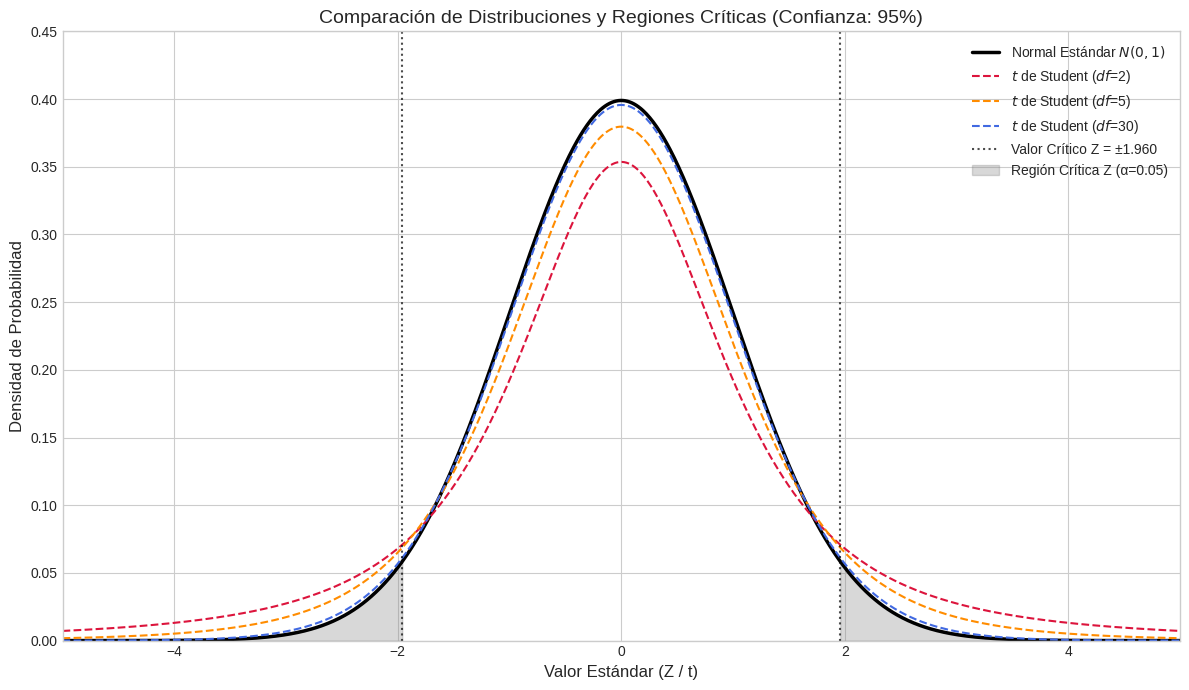

In [3]:
# Configuración del gráfico
x = np.linspace(-5, 5, 1000)
confianza = 0.95
alfa = 1 - confianza

fig, ax = plt.subplots(figsize=(12, 7))

# Graficar Normal Estándar
y_norm = stats.norm.pdf(x)
ax.plot(x, y_norm, label='Normal Estándar $N(0,1)$', color='black', linewidth=2.5)

# Graficar t de Student para diferentes df
colores_t = {2: 'crimson', 5: 'darkorange', 30: 'royalblue'}
for df in [2, 5, 30]:
    y_t = stats.t.pdf(x, df)
    ax.plot(x, y_t, label=f'$t$ de Student ($df$={df})', color=colores_t[df], linestyle='--')

# Mostrar valores críticos para la Normal Estándar en 95%
z_critico = stats.norm.ppf(1 - alfa/2)
ax.axvline(z_critico, color='black', linestyle=':', alpha=0.7, label=f'Valor Crítico Z = ±{z_critico:.3f}')
ax.axvline(-z_critico, color='black', linestyle=':', alpha=0.7)

# Sombrear la región crítica de dos colas para la Normal Estándar
x_fill_izq = np.linspace(-5, -z_critico, 100)
x_fill_der = np.linspace(z_critico, 5, 100)
ax.fill_between(x_fill_izq, stats.norm.pdf(x_fill_izq), color='gray', alpha=0.3, label=f'Región Crítica Z (α={alfa:.2f})')
ax.fill_between(x_fill_der, stats.norm.pdf(x_fill_der), color='gray', alpha=0.3)

# Detalles del gráfico
ax.set_title(f'Comparación de Distribuciones y Regiones Críticas (Confianza: {int(confianza*100)}%)', fontsize=14)
ax.set_xlabel('Valor Estándar (Z / t)', fontsize=12)
ax.set_ylabel('Densidad de Probabilidad', fontsize=12)
ax.legend(loc='upper right', fontsize=10)
ax.set_xlim(-5, 5)
ax.set_ylim(0, 0.45)

plt.tight_layout()
plt.show()

### 3. Cálculo y Visualización de la Probabilidad Acumulada

A continuación, calculamos la probabilidad acumulada (área bajo la curva a la izquierda de un valor crítico dado $x_{critico}$) para la distribución Normal Estándar y la distribución $t$ de Student. Puedes ajustar los parámetros en la celda de abajo para experimentar con diferentes valores.

In [7]:
# @title Parámetros de Análisis
valor_critico = 1.990  # @param {type:"number"}
grados_libertad_acumulada = 79  # @param {type:"integer"}

# Cálculo de probabilidades acumuladas (CDF)
prob_acum_normal = stats.norm.cdf(valor_critico)
prob_acum_t = stats.t.cdf(valor_critico, df=grados_libertad_acumulada)

print(f"Para un valor crítico x = {valor_critico}:")
print(f"- Probabilidad acumulada en Normal Estándar N(0,1): {prob_acum_normal:.4f} (P(X <= {valor_critico}))")
print(f"- Probabilidad acumulada en t de Student (df={grados_libertad_acumulada}): {prob_acum_t:.4f} (P(X <= {valor_critico}))")

Para un valor crítico x = 1.99:
- Probabilidad acumulada en Normal Estándar N(0,1): 0.9767 (P(X <= 1.99))
- Probabilidad acumulada en t de Student (df=79): 0.9750 (P(X <= 1.99))


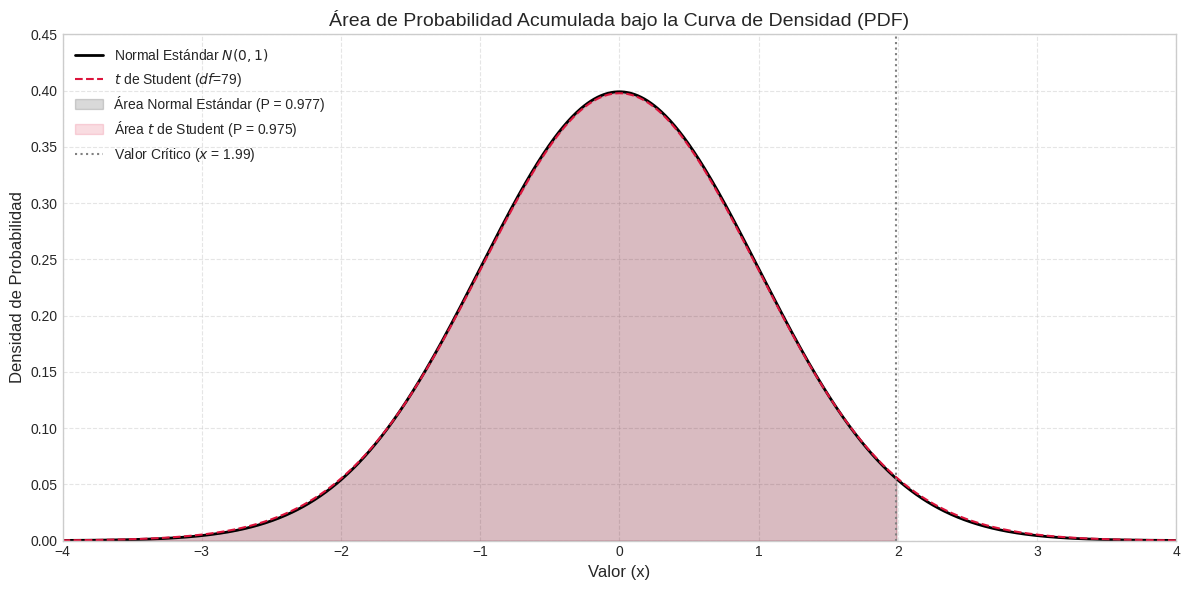

In [8]:
# Gráfico de la Función de Densidad de Probabilidad (PDF) con áreas sombreadas
x_vals = np.linspace(-4, 4, 1000)

fig, ax = plt.subplots(figsize=(12, 6))

# Curvas de densidad de probabilidad (PDF)
y_norm = stats.norm.pdf(x_vals)
y_t = stats.t.pdf(x_vals, df=grados_libertad_acumulada)

ax.plot(x_vals, y_norm, label='Normal Estándar $N(0,1)$', color='black', linewidth=2)
ax.plot(x_vals, y_t, label=f'$t$ de Student ($df$={grados_libertad_acumulada})', color='crimson', linestyle='--')

# Límites para el sombreado (desde el extremo izquierdo hasta el valor crítico)
x_sombrear = np.linspace(-4, valor_critico, 500)

# Sombrear el área para la Normal Estándar
ax.fill_between(x_sombrear, stats.norm.pdf(x_sombrear), color='black', alpha=0.15,
                label=f'Área Normal Estándar (P = {prob_acum_normal:.3f})')

# Sombrear el área para la t de Student
ax.fill_between(x_sombrear, stats.t.pdf(x_sombrear, df=grados_libertad_acumulada), color='crimson', alpha=0.15,
                label=f'Área $t$ de Student (P = {prob_acum_t:.3f})')

# Línea vertical en el valor crítico
ax.axvline(valor_critico, color='gray', linestyle=':', label=f'Valor Crítico ($x$ = {valor_critico})')

# Detalles del gráfico
ax.set_title('Área de Probabilidad Acumulada bajo la Curva de Densidad (PDF)', fontsize=14)
ax.set_xlabel('Valor (x)', fontsize=12)
ax.set_ylabel('Densidad de Probabilidad', fontsize=12)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xlim(-4, 4)
ax.set_ylim(0, 0.45)

plt.tight_layout()
plt.show()

### 4. Cálculo de Valor Crítico a partir de una Probabilidad Acumulada

En esta sección realizamos el proceso inverso: dada una probabilidad acumulada (área a la izquierda, $P(X \leq x)$) y los grados de libertad, calculamos el valor crítico correspondiente (función cuantil o percentil) para la distribución Normal y la $t$ de Student.

In [15]:
# @title Parámetros para Cálculo Inverso
probabilidad_acumulada_objetivo = 0.975  # @param {type:"number"}
grados_libertad_inverso = 79  # @param {type:"integer"}

# Cálculo de los valores críticos (PPF - Percent Point Function)
val_critico_normal_inv = stats.norm.ppf(probabilidad_acumulada_objetivo)
val_critico_t_inv = stats.t.ppf(probabilidad_acumulada_objetivo, df=grados_libertad_inverso)

print(f"Para una probabilidad acumulada objetivo de {probabilidad_acumulada_objetivo} (área a la izquierda):")
print(f"- Valor crítico en Normal Estándar Z: {val_critico_normal_inv:.4f}")
print(f"- Valor crítico en t de Student (df={grados_libertad_inverso}): {val_critico_t_inv:.4f}")

Para una probabilidad acumulada objetivo de 0.975 (área a la izquierda):
- Valor crítico en Normal Estándar Z: 1.9600
- Valor crítico en t de Student (df=79): 1.9905
